# Car Price Prediction
**Source:** [Kaggle — Vehicle Dataset from CarDekho](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)  
**Target:** `selling_price` (INR). **Models:** Linear Regression, Random Forest, Gradient Boosting.

> **Reproducibility:** This notebook downloads a real Kaggle dataset when network access is available. If the download is blocked, manually put `car details v4.csv` (preferred) or `CAR DETAILS FROM CAR DEKHO.csv` in `data/`. No synthetic observations are used. Outputs are generated from real observations only. The dataset's listed prices are historical asking/selling prices, not current market valuations.

## 1. Imports and settings

In [20]:
# Uncomment in a fresh environment if needed:
# %pip install pandas numpy matplotlib seaborn scikit-learn kagglehub joblib nbformat
import re, warnings, pathlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Uncomment in a fresh environment if needed:
# %pip install pandas numpy matplotlib seaborn scikit-learn kagglehub joblib nbformat
import re, warnings, pathlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize':(10,5),'figure.dpi':110})
ROOT=pathlib.Path.cwd(); DATA=ROOT/'data'; OUT=ROOT/'outputs'; CHARTS=OUT/'charts'
DATA.mkdir(exist_ok=True); CHARTS.mkdir(parents=True,exist_ok=True)
RANDOM_STATE=42

def save_plot(name):
    plt.tight_layout(); plt.savefig(CHARTS/f'{name}.png',dpi=180,bbox_inches='tight'); plt.show()

def note(text):
    display(Markdown('**Observation.** '+str(text)))
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize':(10,5),'figure.dpi':110})
ROOT=pathlib.Path.cwd(); DATA=ROOT/'data'; OUT=ROOT/'outputs'; CHARTS=OUT/'charts'
DATA.mkdir(exist_ok=True); CHARTS.mkdir(parents=True,exist_ok=True)
RANDOM_STATE=42

def save_plot(name):
    plt.tight_layout(); plt.savefig(CHARTS/f'{name}.png',dpi=180,bbox_inches='tight'); plt.show()

def note(text):
    display(Markdown('**Observation.** '+str(text)))

## 2. Download and inspect the genuine Kaggle dataset

In [21]:
import pathlib

# Prefer the richer CarDekho v4 CSV, which includes engine, mileage, power and seats.
# ##if 'DATA' not in globals():
#     DATA = pathlib.Path.cwd() / 'data'
#     DATA.mkdir(exist_ok=True)
# files = list(DATA.glob('*.csv'))
# if not files:
#     try:
#         import kagglehub
# import subprocess, sys
#         downloaded=pathlib.Path(kagglehub.dataset_download('nehalbirla/vehicle-dataset-from-cardekho'))
#         files=list(downloaded.rglob('*.csv'))
#         print('Kaggle dataset downloaded to:',downloaded)
#     except Exception as exc:
#         try:
#             subprocess.run(
#             [sys.executable, "-m", "pip", "install", "kagglehub"],
#             check=True,
#             capture_output=True,
#             text=True,
#             )
#             downloaded = pathlib.Path(kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho"))
#             files = list(downloaded.rglob("*.csv"))
#             print("Kaggle dataset downloaded to:", downloaded)
#         except Exception as install_exc:
#             raise FileNotFoundError(
#             "Kaggle download unavailable. Install kagglehub with 'pip install kagglehub' "
#             "or download from https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho "
#             "and place a CSV inside data/. Original error: "
#             + str(install_exc)
#             ) from install_exc
# if not files: raise FileNotFoundError('No CSV found in downloaded Kaggle dataset.')
# files=sorted(files,key=lambda f:(('v4' not in f.name.lower()),('car details' not in f.name.lower()),f.name))
# source_file=files[0]##

csv_files = list(DATA.glob('*.csv'))
if not csv_files:
	raise FileNotFoundError(f'No CSV files found in {DATA}. Place the dataset CSV in this folder.')
source_file = sorted(
	csv_files,
	key=lambda path: ('v4' not in path.name.lower(),
					  'car details' not in path.name.lower(),
					  path.name.lower())
)[0]
df = pd.read_csv(source_file)
print('Source:', source_file, '| shape:', df.shape)
display(df.head(10)); display(df.tail(10)); display(df.describe(include='all').T)
print('Columns:',df.columns.tolist());print('Duplicates:',df.duplicated().sum())
print('Missing values:');display(df.isna().sum().to_frame('missing'))
df.info()

Source: c:\Users\navee\Desktop\Projects\Car price Prediction\data\cd_v4.csv | shape: (2059, 20)


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0
5,Maruti Suzuki,Ciaz ZXi,675000,2017,73315,Petrol,Manual,Pune,Grey,First,Individual,1373 cc,91 bhp @ 6000 rpm,130 Nm @ 4000 rpm,FWD,4490.0,1730.0,1485.0,5.0,43.0
6,Mercedes-Benz,CLA 200 Petrol Sport,1898999,2015,47000,Petrol,Automatic,Mumbai,White,Second,Individual,1991 cc,181 bhp @ 5500 rpm,300 Nm @ 1200 rpm,FWD,4630.0,1777.0,1432.0,5.0,NaN
7,BMW,X1 xDrive20d M Sport,2650000,2017,75000,Diesel,Automatic,Coimbatore,White,Second,Individual,1995 cc,188 bhp @ 4000 rpm,400 Nm @ 1750 rpm,AWD,4439.0,1821.0,1612.0,5.0,51.0
8,Skoda,Octavia 1.8 TSI Style Plus AT [2017],1390000,2017,56000,Petrol,Automatic,Mumbai,White,First,Individual,1798 cc,177 bhp @ 5100 rpm,250 Nm @ 1250 rpm,FWD,4670.0,1814.0,1476.0,5.0,50.0
9,Nissan,Terrano XL (D),575000,2015,85000,Diesel,Manual,Mumbai,White,First,Individual,1461 cc,84 bhp @ 3750 rpm,200 Nm @ 1900 rpm,FWD,4331.0,1822.0,1671.0,5.0,50.0


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
2049,Mercedes-Benz,GLS 400 4MATIC,5950000,2017,80000,Petrol,Automatic,Delhi,Black,First,Individual,2996 cc,329 bhp @ 5250 rpm,480 Nm @ 1600 rpm,AWD,5130.0,1934.0,1850.0,5.0,100.0
2050,Hyundai,Creta SX Plus 1.6 Petrol,891000,2016,47000,Petrol,Manual,Delhi,White,First,Individual,1591 cc,122 bhp @ 6400 rpm,154 Nm @ 4850 rpm,FWD,4270.0,1780.0,1630.0,5.0,60.0
2051,Maruti Suzuki,Vitara Brezza VXi,925000,2021,48000,Petrol,Manual,Bangalore,White,First,Individual,1462 cc,103 bhp @ 6000 rpm,138 Nm @ 4400 rpm,FWD,3995.0,1790.0,1640.0,5.0,48.0
2052,Hyundai,i20 Sportz 1.4 CRDI,409999,2014,68000,Diesel,Manual,Agra,Silver,First,Individual,1396 cc,90@4000,220@1750,NaN,3940.0,1710.0,1505.0,5.0,45.0
2053,Maruti Suzuki,Ritz Vxi (ABS) BS-IV,245000,2014,79000,Petrol,Manual,Faridabad,White,Second,Individual,1197 cc,85 bhp @ 6000 rpm,113 Nm @ 4500 rpm,FWD,3775.0,1680.0,1620.0,5.0,43.0
2054,Mahindra,XUV500 W8 [2015-2017],850000,2016,90300,Diesel,Manual,Surat,White,First,Individual,2179 cc,138 bhp @ 3750 rpm,330 Nm @ 1600 rpm,FWD,4585.0,1890.0,1785.0,7.0,70.0
2055,Hyundai,Eon D-Lite +,275000,2014,83000,Petrol,Manual,Ahmedabad,White,Second,Individual,814 cc,55 bhp @ 5500 rpm,75 Nm @ 4000 rpm,FWD,3495.0,1550.0,1500.0,5.0,32.0
2056,Ford,Figo Duratec Petrol ZXI 1.2,240000,2013,73000,Petrol,Manual,Thane,Silver,First,Individual,1196 cc,70 bhp @ 6250 rpm,102 Nm @ 4000 rpm,FWD,3795.0,1680.0,1427.0,5.0,45.0
2057,BMW,5-Series 520d Luxury Line [2017-2019],4290000,2018,60474,Diesel,Automatic,Coimbatore,White,First,Individual,1995 cc,188 bhp @ 4000 rpm,400 Nm @ 1750 rpm,RWD,4936.0,1868.0,1479.0,5.0,65.0
2058,Mahindra,Bolero Power Plus ZLX [2016-2019],670000,2017,72000,Diesel,Manual,Guwahati,White,First,Individual,1493 cc,70 bhp @ 3600 rpm,195 Nm @ 1400 rpm,RWD,3995.0,1745.0,1880.0,7.0,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Make,2059,33,Maruti Suzuki,440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,2059,1050,X1 sDrive20d xLine,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,2059.0,NaN,NaN,NaN,1702991.696455,2419880.635434,49000.0,484999.0,825000.0,1925000.0,35000000.0
Year,2059.0,NaN,NaN,NaN,2016.425449,3.363564,1988.0,2014.0,2017.0,2019.0,2022.0
Kilometer,2059.0,NaN,NaN,NaN,54224.714424,57361.721314,0.0,29000.0,50000.0,72000.0,2000000.0
Fuel Type,2059,9,Diesel,1049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,2059,2,Manual,1133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,2059,77,Mumbai,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,2059,17,White,802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,2059,6,First,1619,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Columns: ['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']
Duplicates: 0
Missing values:


,missing
Make,0
Model,0
Price,0
Year,0
Kilometer,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0


<class 'pandas.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   str    
 1   Model               2059 non-null   str    
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   str    
 6   Transmission        2059 non-null   str    
 7   Location            2059 non-null   str    
 8   Color               2059 non-null   str    
 9   Owner               2059 non-null   str    
 10  Seller Type         2059 non-null   str    
 11  Engine              1979 non-null   str    
 12  Max Power           1979 non-null   str    
 13  Max Torque          1979 non-null   str    
 14  Drivetrain          1923 non-null   str    
 15  Length              1995 non-null   float64
 16  Width            

## 3. Cleaning: standardization, validation, missingness and duplicates

C:\Users\navee\AppData\Local\Temp\ipykernel_13292\394106428.py:27: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


Removed 0 duplicate or invalid-target records.


,nulls,null_pct
make,0,0.00
model,0,0.00
selling_price,0,0.00
year,0,0.00
km_driven,0,0.00
fuel,0,0.00
transmission,0,0.00
location,0,0.00
color,0,0.00
owner,0,0.00


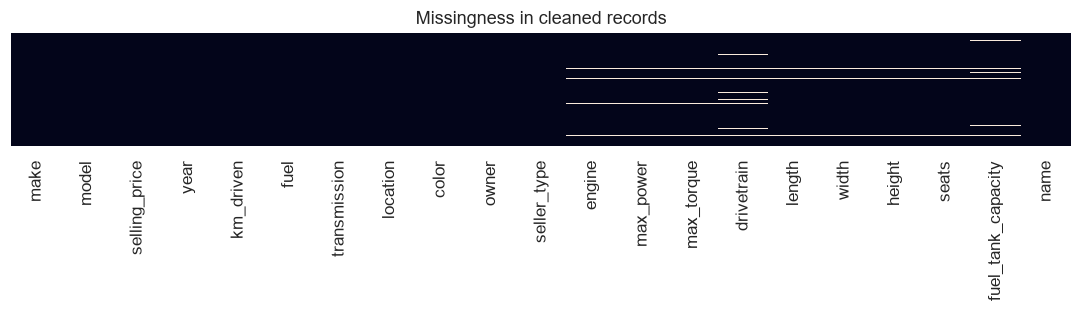

**Observation.** Missing predictors are retained for training-only pipeline imputation. Missing or nonpositive target prices are excluded. Outliers are inspected, not automatically deleted.

In [22]:
raw=df.copy()
df.columns=[re.sub(r'[^a-z0-9]+','_',str(c).strip().lower()).strip('_') for c in df.columns]
rename={'selling_price':'selling_price','km_driven':'km_driven','owner':'owner','name':'name','year':'year','fuel':'fuel','seller_type':'seller_type','transmission':'transmission'}
df=df.rename(columns=rename)
# Map the v4 dataset's column names to the names used by the rest of the notebook.
aliases = {
    'price': 'selling_price',
    'kilometer': 'km_driven',
    'fuel_type': 'fuel',
    'seating_capacity': 'seats',
}
for source, target in aliases.items():
    if source in df.columns and target not in df.columns:
        df = df.rename(columns={source: target})

# The v4 dataset stores make and model separately; create the name field
# expected by the feature-engineering cell.
if 'name' not in df.columns and {'make', 'model'}.issubset(df.columns):
    df['name'] = df['make'].fillna('').astype(str) + ' ' + df['model'].fillna('').astype(str)
    df['name'] = df['name'].str.strip()

if 'selling_price' not in df.columns:
    raise ValueError(
        'Dataset must contain a price column. Available columns: '
        + str(df.columns.tolist())
    )
for col in df.select_dtypes(include='object').columns:
    df[col]=df[col].astype('string').str.strip()
for col in ['fuel','seller_type','transmission','owner']:
    if col in df: df[col]=df[col].str.lower().str.replace(r'\s+',' ',regex=True).str.title()
# Convert strings with physical units into numeric values; avoid mixing incompatible units.
for col in ['selling_price','year','km_driven','engine','max_power','seats','mileage']:
    if col in df:
        text=df[col].astype('string').str.replace(',','',regex=False)
        if col=='mileage':
            # km/kg and km/l are not equivalent; retain the unit separately.
            df['mileage_unit']=np.where(text.str.contains('km/kg',case=False,na=False),'km/kg',np.where(text.str.contains('kmpl',case=False,na=False),'km/l',pd.NA))
        df[col]=pd.to_numeric(text.str.extract(r'([-+]?\d*\.?\d+)')[0],errors='coerce')
if 'mileage_unit' in df:
    # Mileage in km/kg and km/l are incomparable; exclude the raw number unless unit known.
    df.loc[df['mileage_unit']!='km/l','mileage']=np.nan
before=len(df)
df=df.drop_duplicates().copy()
df=df[df.selling_price.notna() & (df.selling_price>0)].copy()
for col in ['km_driven','engine','max_power','mileage','seats']:
    if col in df: df.loc[df[col]<0,col]=np.nan
if 'year' in df: df.loc[~df.year.between(1950,2026),'year']=np.nan
print('Removed',before-len(df),'duplicate or invalid-target records.')
display(pd.DataFrame({'nulls':df.isna().sum(),'null_pct':(df.isna().mean()*100).round(2)}))
plt.figure(figsize=(10,3));sns.heatmap(df.isna(),cbar=False,yticklabels=False);plt.title('Missingness in cleaned records');save_plot('missingness')
note('Missing predictors are retained for training-only pipeline imputation. Missing or nonpositive target prices are excluded. Outliers are inspected, not automatically deleted.')

## 4. Feature engineering and descriptive statistics

In [23]:
# A fixed historical reference year avoids silently treating old listings as current listings.
REFERENCE_YEAR=2020
if 'name' in df:
    df['brand']=df['name'].str.split().str[0].str.title()
    df['brand']=df['brand'].replace({'Land':'Land Rover','Mercedes-Benz':'Mercedes-Benz'})
if 'year' in df:
    df['car_age']=REFERENCE_YEAR-df['year']
    df.loc[df.car_age<0,'car_age']=np.nan
if 'km_driven' in df and 'car_age' in df:
    df['km_per_year']=df['km_driven']/df['car_age'].clip(lower=1)
if 'engine' in df and 'max_power' in df:
    df['power_per_cc']=df['max_power']/df['engine'].replace(0,np.nan)
print('Records:',len(df),'| Brands:',df.brand.nunique() if 'brand' in df else 'unavailable')
print('Price (INR): mean',round(df.selling_price.mean()),'median',round(df.selling_price.median()))
display(df.describe().T)
df.to_csv(OUT/'Car_Price_Cleaned_Dataset.csv',index=False)
note(f'Median recorded selling price: ₹{df.selling_price.median():,.0f}; mean: ₹{df.selling_price.mean():,.0f}. These figures reflect the selected Kaggle listings, not the entire Indian car market.')

Records: 2059 | Brands: 33
Price (INR): mean 1702992 median 825000


,count,mean,std,min,25%,50%,75%,max
selling_price,2059.0,1702991.696455,2419880.635434,49000.0,484999.0,825000.0,1925000.0,35000000.0
year,2059.0,2016.425449,3.363564,1988.0,2014.0,2017.0,2019.0,2022.0
km_driven,2059.0,54224.714424,57361.721314,0.0,29000.0,50000.0,72000.0,2000000.0
engine,1979.0,1692.575543,643.736294,624.0,1197.0,1498.0,1995.0,6592.0
max_power,1979.0,129.611774,65.073797,35.0,83.0,116.0,171.0,660.0
length,1995.0,4280.860652,442.458507,3099.0,3985.0,4370.0,4629.0,5569.0
width,1995.0,1767.99198,135.265825,1475.0,1695.0,1770.0,1831.5,2220.0
height,1995.0,1591.735338,136.073956,1165.0,1485.0,1545.0,1675.0,1995.0
seats,1995.0,5.306266,0.82217,2.0,5.0,5.0,5.0,8.0
fuel_tank_capacity,1946.0,52.00221,15.110198,15.0,41.25,50.0,60.0,105.0


**Observation.** Median recorded selling price: ₹825,000; mean: ₹1,702,992. These figures reflect the selected Kaggle listings, not the entire Indian car market.

## 5. Exploratory data analysis — distribution and outliers

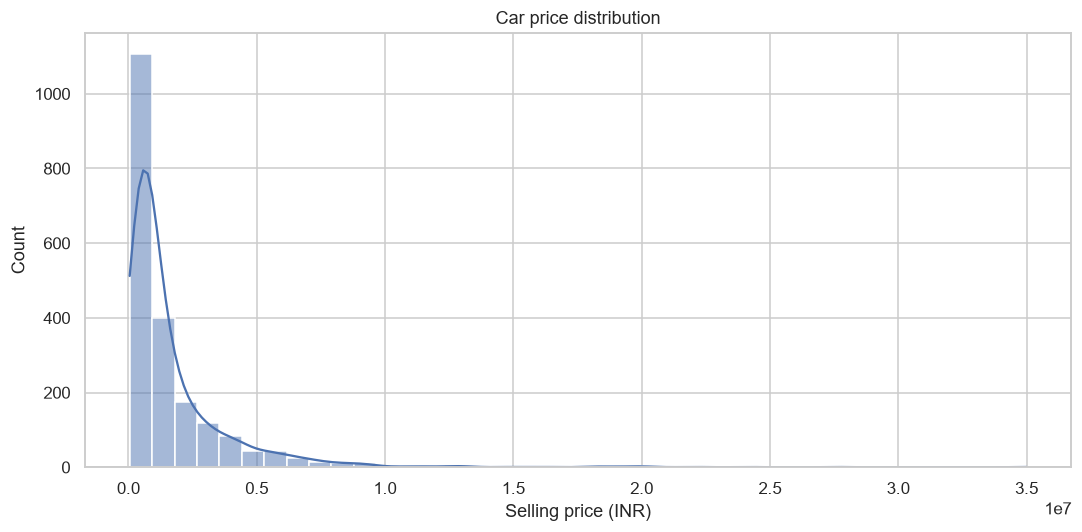

**Observation.** The distribution has skewness 4.97; mean ₹1,702,992 versus median ₹825,000.

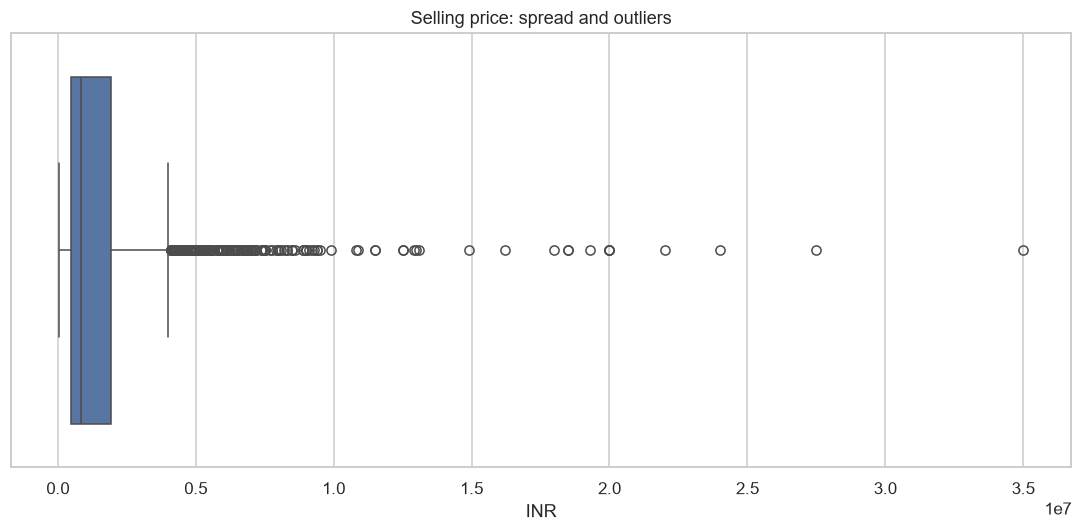

**Observation.** IQR upper fence ₹4,085,002; 215 observations exceed it. Such listings may be genuine premium vehicles and are retained.

In [24]:
fig,ax=plt.subplots();sns.histplot(df.selling_price,kde=True,ax=ax,bins=40);ax.set(xlabel='Selling price (INR)',title='Car price distribution');save_plot('price_distribution')
note(f'The distribution has skewness {df.selling_price.skew():.2f}; mean ₹{df.selling_price.mean():,.0f} versus median ₹{df.selling_price.median():,.0f}.')
fig,ax=plt.subplots();sns.boxplot(x=df.selling_price,ax=ax);ax.set(title='Selling price: spread and outliers',xlabel='INR');save_plot('price_boxplot')
q1,q3=df.selling_price.quantile([.25,.75]); upper=q3+1.5*(q3-q1)
note(f'IQR upper fence ₹{upper:,.0f}; {(df.selling_price>upper).sum():,} observations exceed it. Such listings may be genuine premium vehicles and are retained.')

## 6. Scatterplots and categorical comparisons

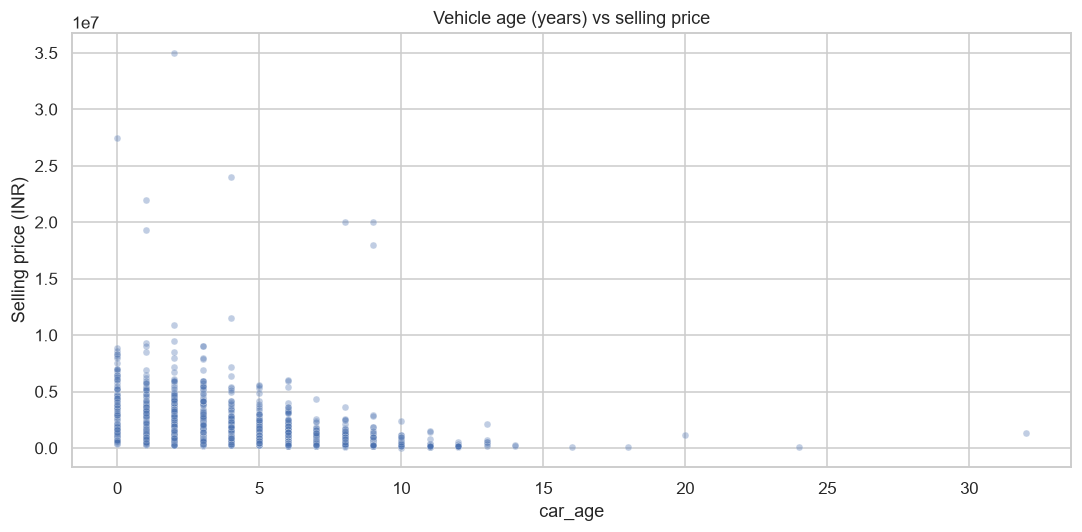

**Observation.** Vehicle age (years) has a Pearson correlation of -0.25 with price. This association does not establish causation.

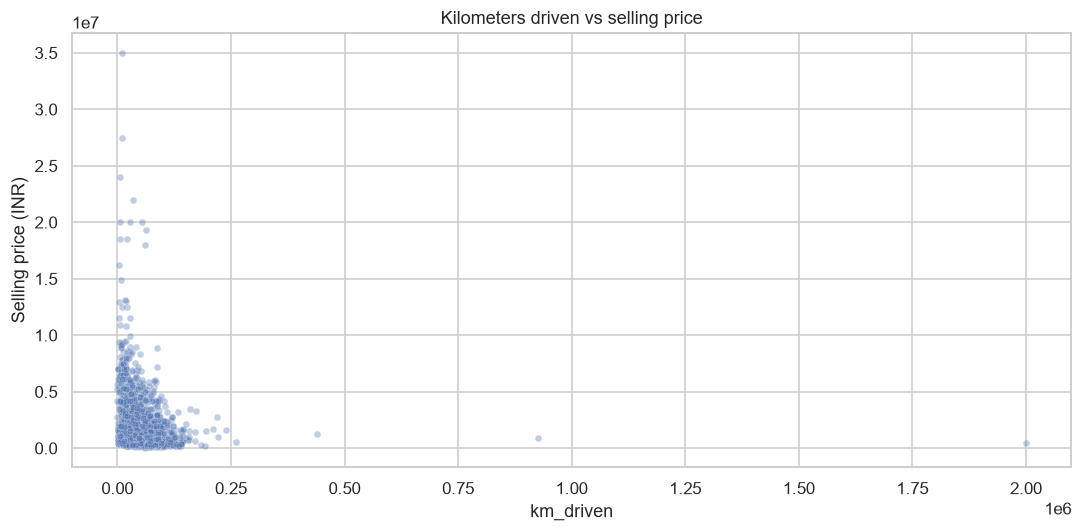

**Observation.** Kilometers driven has a Pearson correlation of -0.15 with price. This association does not establish causation.

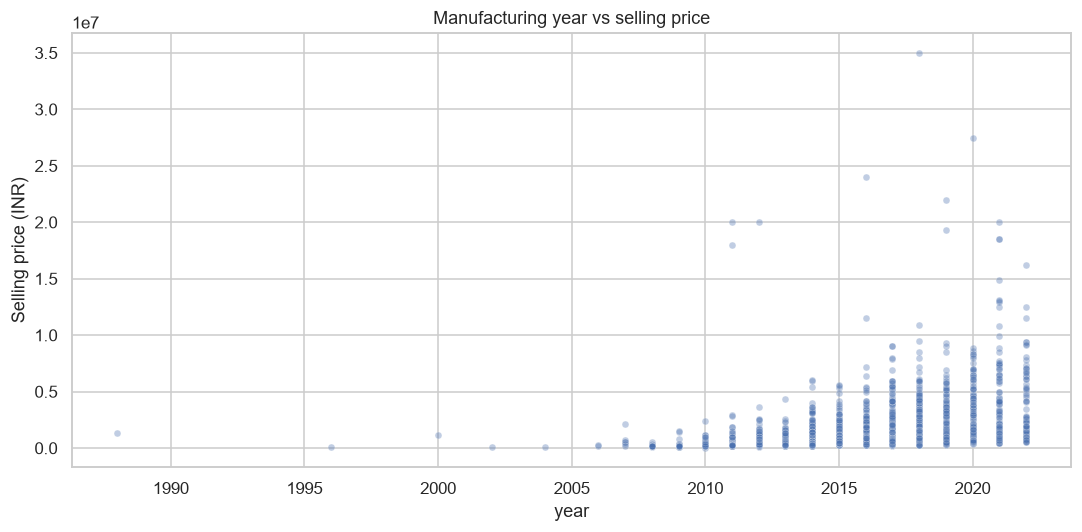

**Observation.** Manufacturing year has a Pearson correlation of 0.31 with price. This association does not establish causation.

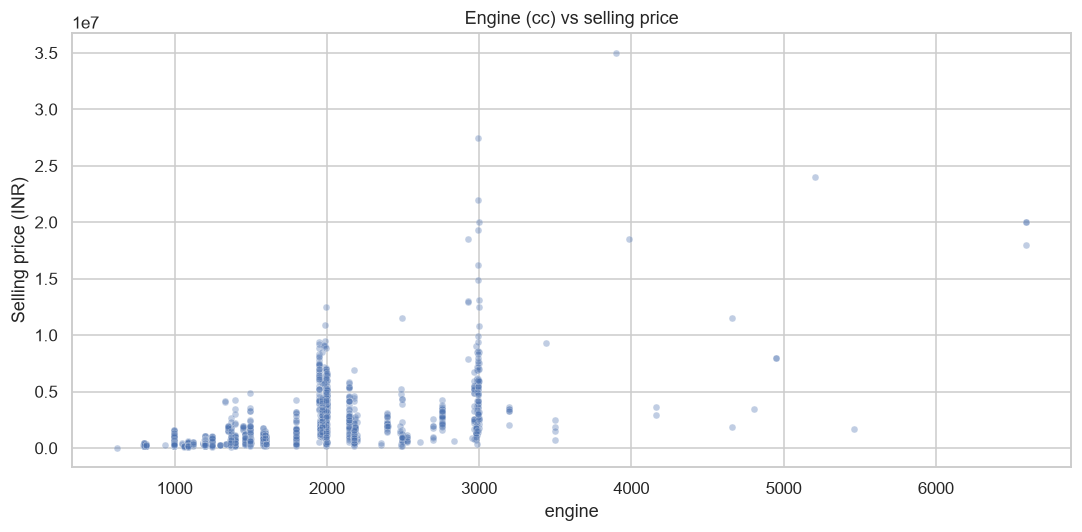

**Observation.** Engine (cc) has a Pearson correlation of 0.62 with price. This association does not establish causation.

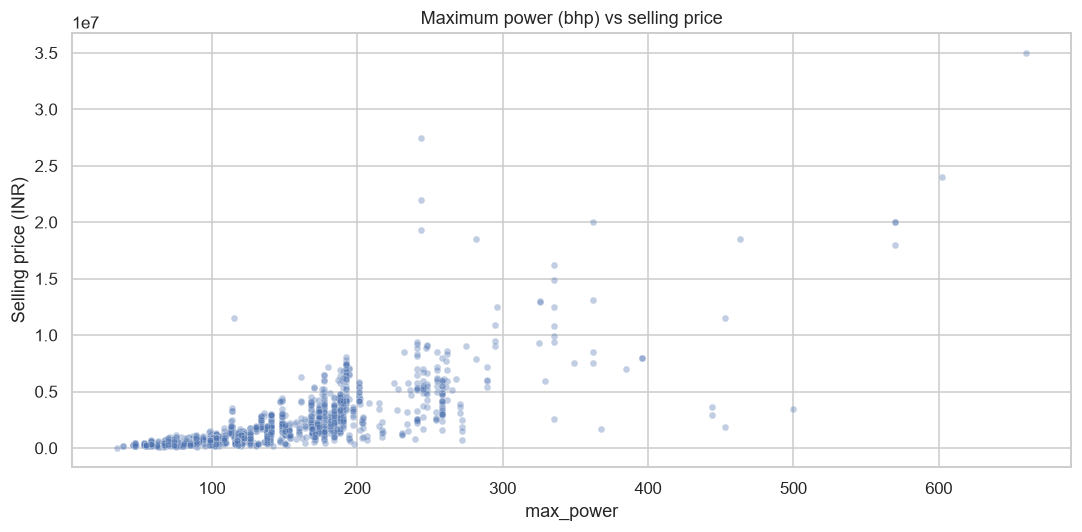

**Observation.** Maximum power (bhp) has a Pearson correlation of 0.78 with price. This association does not establish causation.

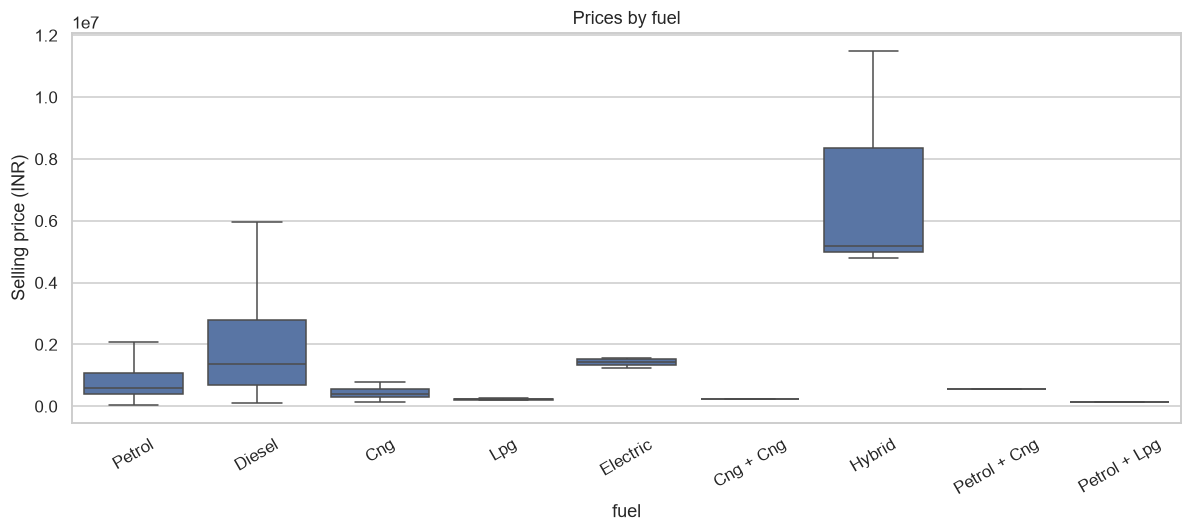

**Observation.** Highest median price category: Hybrid (₹5,200,000); comparisons may reflect differing car mixes.

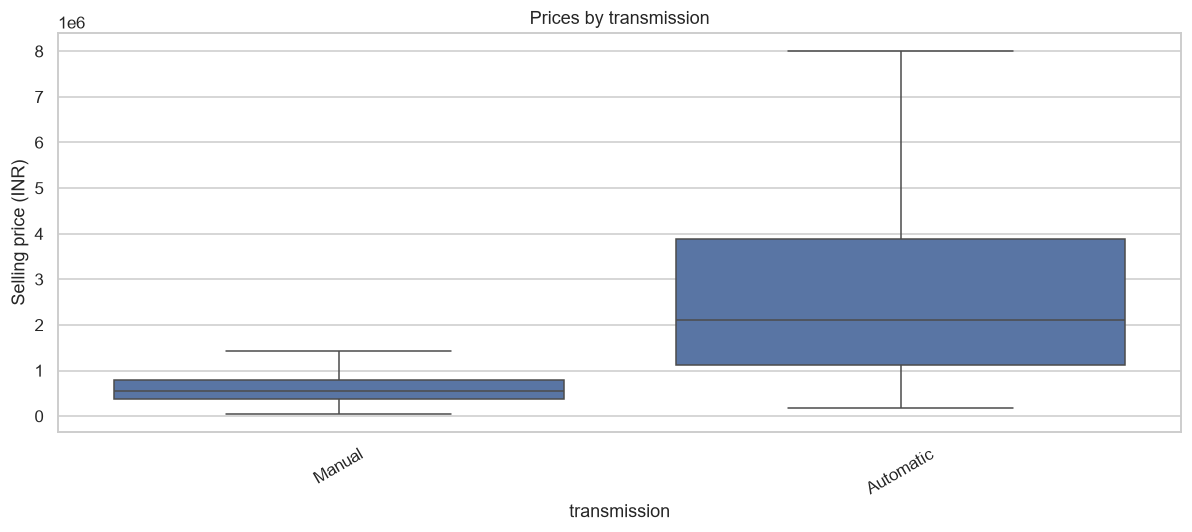

**Observation.** Highest median price category: Automatic (₹2,100,000); comparisons may reflect differing car mixes.

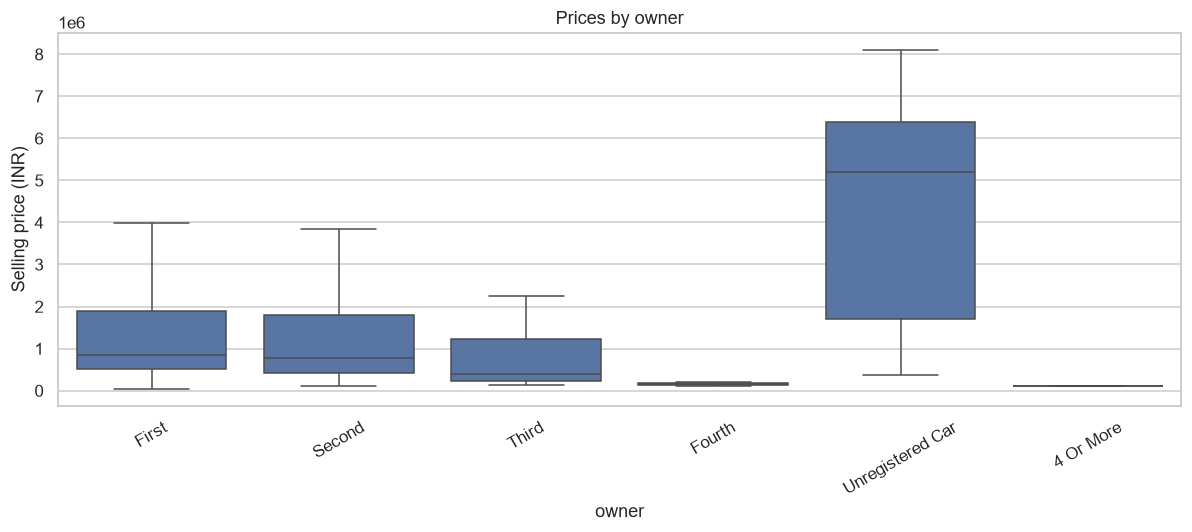

**Observation.** Highest median price category: Unregistered Car (₹5,200,000); comparisons may reflect differing car mixes.

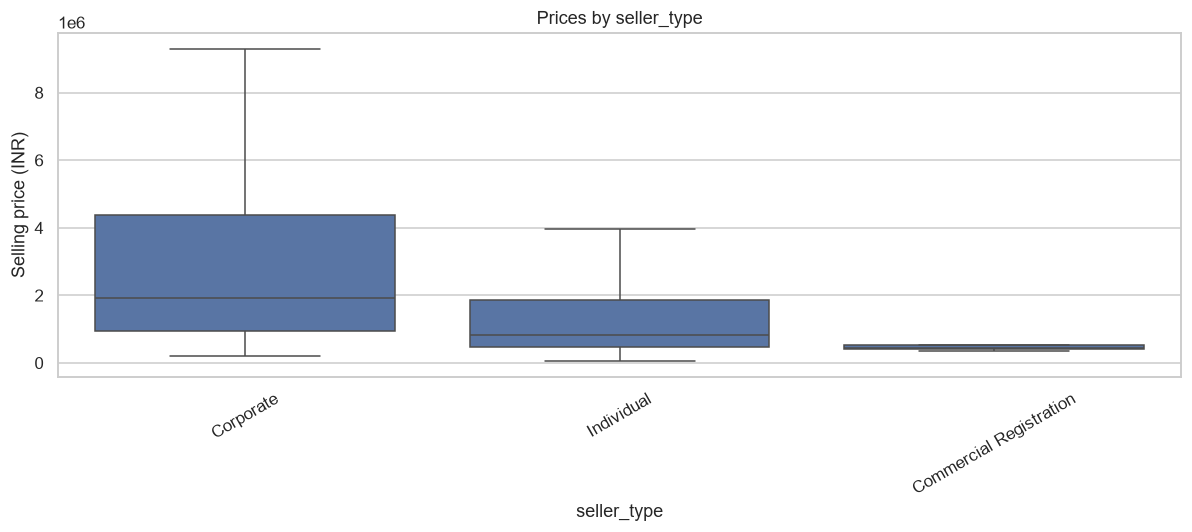

**Observation.** Highest median price category: Corporate (₹1,925,000); comparisons may reflect differing car mixes.

In [25]:
for x,label in [('car_age','Vehicle age (years)'),('km_driven','Kilometers driven'),('year','Manufacturing year'),('engine','Engine (cc)'),('max_power','Maximum power (bhp)')]:
    if x in df and df[x].notna().sum()>5:
        fig,ax=plt.subplots();sns.scatterplot(data=df,x=x,y='selling_price',alpha=.35,s=20,ax=ax)
        ax.set(title=f'{label} vs selling price',ylabel='Selling price (INR)');save_plot('scatter_'+x)
        corr=df[[x,'selling_price']].corr().iloc[0,1]
        note(f'{label} has a Pearson correlation of {corr:.2f} with price. This association does not establish causation.')
for col in ['fuel','transmission','owner','seller_type']:
    if col in df and df[col].nunique(dropna=True)<20:
        fig,ax=plt.subplots(figsize=(11,5));sns.boxplot(data=df,x=col,y='selling_price',ax=ax,showfliers=False)
        ax.tick_params(axis='x',rotation=30);ax.set(title=f'Prices by {col}',ylabel='Selling price (INR)');save_plot('box_'+col)
        med=df.groupby(col).selling_price.median().sort_values(ascending=False)
        note(f'Highest median price category: {med.index[0]} (₹{med.iloc[0]:,.0f}); comparisons may reflect differing car mixes.')

## 7. Brand analysis, correlations, and pairplot

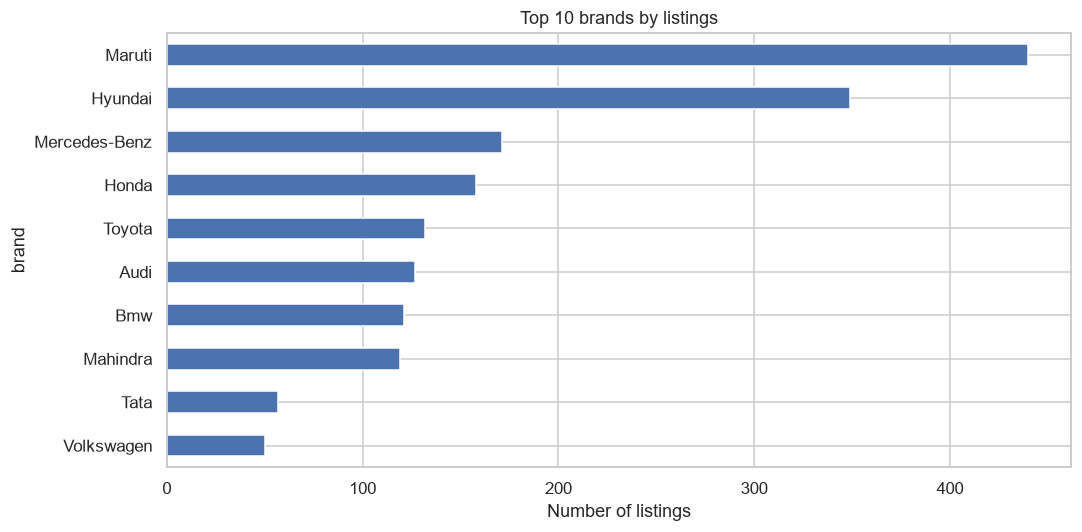

**Observation.** Maruti has the most listings (440).

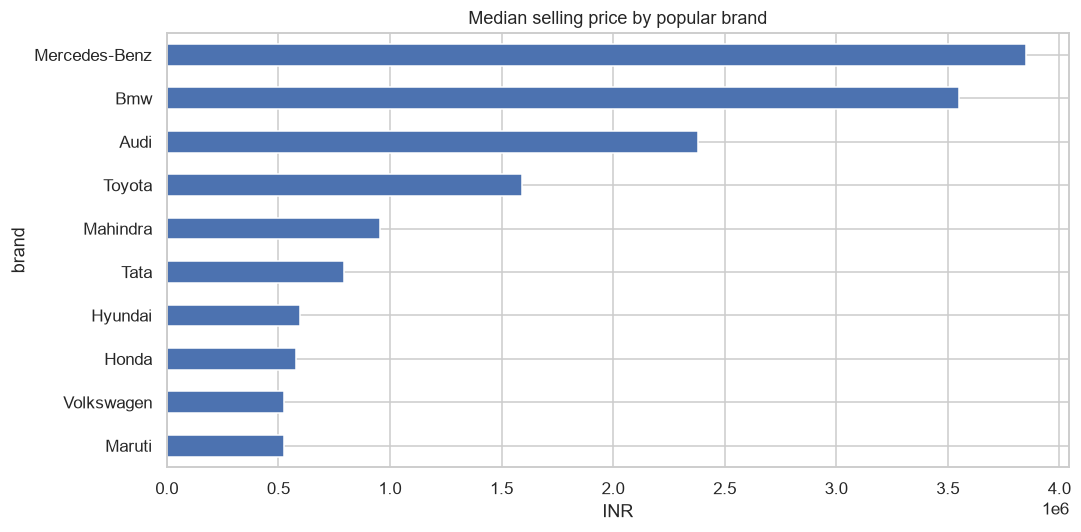

**Observation.** Among the ten most listed brands, Mercedes-Benz has the highest median recorded price (₹3,850,000).

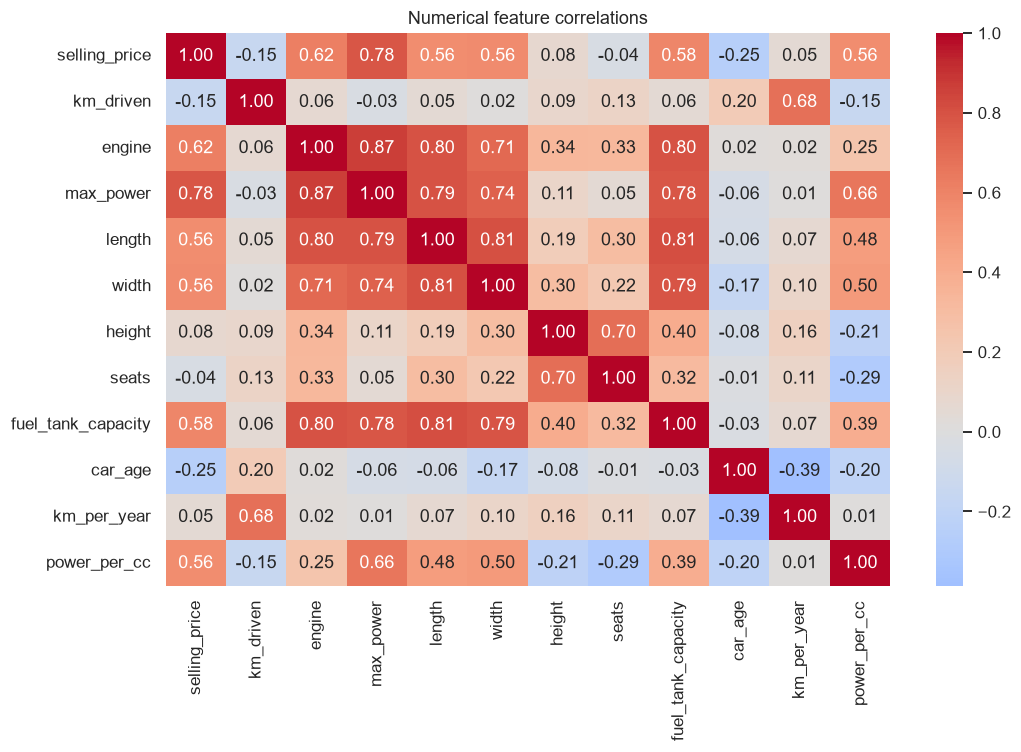

**Observation.** Strongest absolute numerical correlation with price: max_power (0.78). Correlation alone does not justify feature deletion.

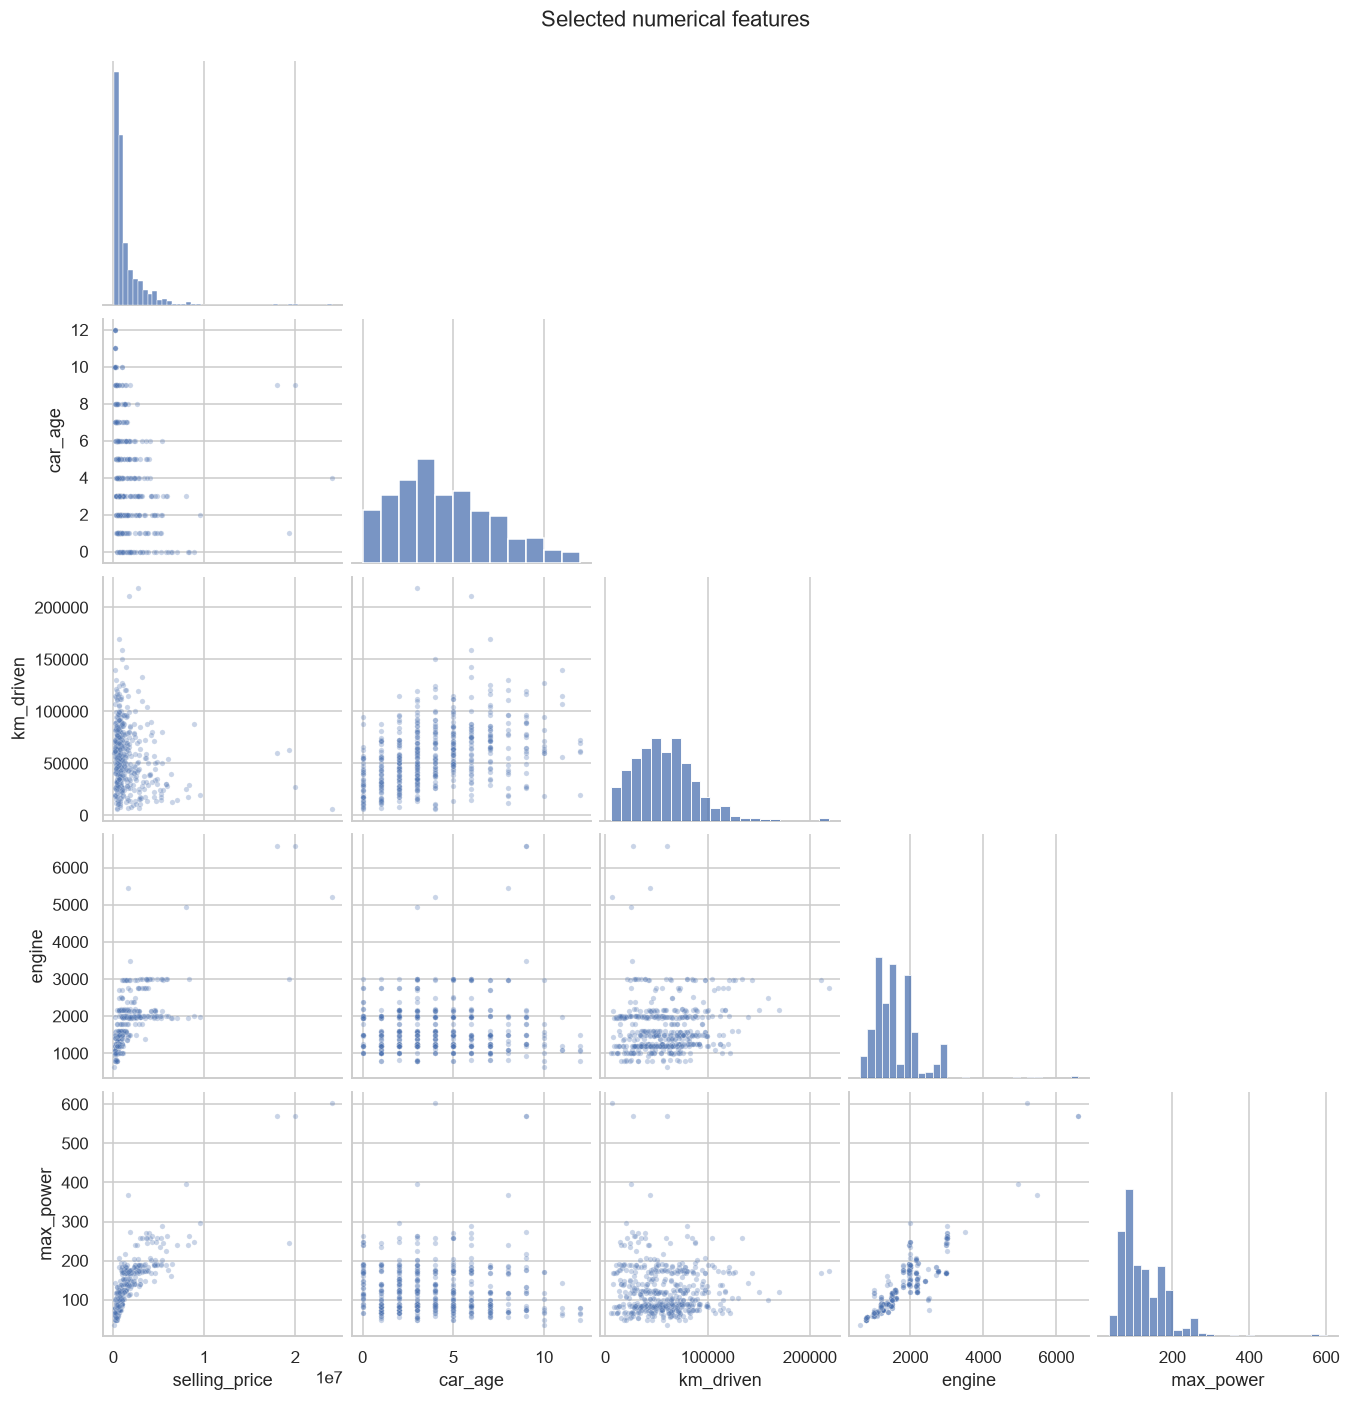

**Observation.** The pairplot highlights nonlinearities, feature correlations, and potential high-value outliers; it is exploratory rather than causal.

In [26]:
if 'brand' in df:
    counts=df.brand.value_counts().head(10).sort_values()
    fig,ax=plt.subplots();counts.plot.barh(ax=ax);ax.set(title='Top 10 brands by listings',xlabel='Number of listings');save_plot('brand_counts')
    note(f'{df.brand.value_counts().index[0]} has the most listings ({df.brand.value_counts().iloc[0]:,}).')
    med=df[df.brand.isin(counts.index)].groupby('brand').selling_price.median().sort_values()
    fig,ax=plt.subplots();med.plot.barh(ax=ax);ax.set(title='Median selling price by popular brand',xlabel='INR');save_plot('brand_prices')
    note(f'Among the ten most listed brands, {med.index[-1]} has the highest median recorded price (₹{med.iloc[-1]:,.0f}).')
num=df.select_dtypes(include=np.number).drop(columns=['year'],errors='ignore')
fig,ax=plt.subplots(figsize=(10,7));sns.heatmap(num.corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=ax);ax.set(title='Numerical feature correlations');save_plot('correlation_heatmap')
cs=num.corr()['selling_price'].drop('selling_price').dropna().sort_values(key=abs,ascending=False)
note('Strongest absolute numerical correlation with price: '+(f'{cs.index[0]} ({cs.iloc[0]:.2f})' if len(cs) else 'not available')+'. Correlation alone does not justify feature deletion.')
cols=[c for c in ['selling_price','car_age','km_driven','engine','max_power'] if c in df]
if len(cols)>=3:
    sample=df[cols].dropna().sample(n=min(500,len(df[cols].dropna())),random_state=42)
    g=sns.pairplot(sample,corner=True,plot_kws={'alpha':.3,'s':12});g.fig.suptitle('Selected numerical features',y=1.02)
    g.fig.savefig(CHARTS/'pairplot.png',dpi=160,bbox_inches='tight');plt.show()
    note('The pairplot highlights nonlinearities, feature correlations, and potential high-value outliers; it is exploratory rather than causal.')

## 8. Leakage-safe preprocessing and 80/20 split

In [27]:
# Keep interpretable features; do not use free-text car names as uncontrolled categories.
exclude={'selling_price','name','year','mileage_unit'}
features=[c for c in df.columns if c not in exclude and df[c].notna().any()]
X=df[features].copy();y=df.selling_price.copy()
num_cols=X.select_dtypes(include=np.number).columns.tolist()
cat_cols=[c for c in X.columns if c not in num_cols]
X[cat_cols]=X[cat_cols].astype('object')
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
print('Train:',len(X_train),'Test:',len(X_test),'Features:',features)
# OneHotEncoder supports older scikit-learn releases.
try: encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError: encoder=OneHotEncoder(handle_unknown='ignore',sparse=False)
def make_preprocessor():
    return ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
        ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',encoder)]),cat_cols)
    ],remainder='drop')
models={
    'Linear Regression':(LinearRegression(),{'model__fit_intercept':[True,False]}),
    'Random Forest':(RandomForestRegressor(random_state=42,n_jobs=-1),{'model__n_estimators':[100,200],'model__max_depth':[None,12],'model__min_samples_leaf':[1,3]}),
    'Gradient Boosting':(GradientBoostingRegressor(random_state=42),{'model__n_estimators':[100,200],'model__learning_rate':[.05,.1],'model__max_depth':[2,3]})
}
cv=KFold(n_splits=5,shuffle=True,random_state=42)

Train: 1647 Test: 412 Features: ['make', 'model', 'km_driven', 'fuel', 'transmission', 'location', 'color', 'owner', 'seller_type', 'engine', 'max_power', 'max_torque', 'drivetrain', 'length', 'width', 'height', 'seats', 'fuel_tank_capacity', 'brand', 'car_age', 'km_per_year', 'power_per_cc']


## 9. Cross-validated hyperparameter tuning and final test metrics

In [ ]:
fitted={};rows=[];predictions={}
for name,(estimator,grid) in models.items():
    pipe=Pipeline([('preprocess',make_preprocessor()),('model',estimator)])
    search=GridSearchCV(pipe,grid,scoring='neg_mean_absolute_error',cv=cv,n_jobs=-1,refit=True)
    # Convert pandas nullable missing values to NumPy NaN before fitting.
    # sklearn imputers cannot handle pd.NA in feature columns.
    X_train = X_train.copy()
    X_test = X_test.copy()
    for col in X_train.columns:
        X_train[col] = X_train[col].astype(object).where(pd.notna(X_train[col]), np.nan)
        X_test[col] = X_test[col].astype(object).where(pd.notna(X_test[col]), np.nan)

    search.fit(X_train, y_train)
    pred=search.predict(X_test)
    fitted[name]=search.best_estimator_;predictions[name]=pred
    rows.append({'Model':name,'MAE':mean_absolute_error(y_test,pred),
                 'RMSE':np.sqrt(mean_squared_error(y_test,pred)),
                 'R2':r2_score(y_test,pred),'CV_MAE':-search.best_score_,
                 'Best_Params':str(search.best_params_)})
results=pd.DataFrame(rows).sort_values(['CV_MAE','MAE']).reset_index(drop=True)
display(results);results.to_csv(OUT/'Car_Price_Model_Comparison.csv',index=False)
best_name=results.iloc[0].Model;best_model=fitted[best_name]
joblib.dump(best_model,OUT/'Best_Car_Price_Model.joblib')
note(f'The model selected by training-fold CV MAE is **{best_name}**. Its held-out MAE is ₹{results.iloc[0].MAE:,.0f}, RMSE ₹{results.iloc[0].RMSE:,.0f}, and R² {results.iloc[0].R2:.3f}.')

## 10. Model comparison, actual versus predicted, and residual diagnostics

In [ ]:
fig,ax=plt.subplots();results.set_index('Model')[['MAE','RMSE']].plot.bar(ax=ax,rot=0);ax.set(ylabel='INR',title='Test errors by regression model');save_plot('model_errors')
note('Lower MAE and RMSE indicate better predictions; RMSE is more sensitive to large errors.')
fig,ax=plt.subplots();sns.barplot(data=results,x='Model',y='R2',ax=ax);ax.set(title='Test R² by model',ylim=(min(-.1,results.R2.min()-.1),max(1,results.R2.max()+.1)));save_plot('model_r2')
note('R² measures improvement over predicting the test-set mean; it can be negative.')
for name,pred in predictions.items():
    fig,ax=plt.subplots();ax.scatter(y_test,pred,alpha=.4,s=18)
    lo=min(y_test.min(),np.min(pred));hi=max(y_test.max(),np.max(pred));ax.plot([lo,hi],[lo,hi],'--',color='black')
    ax.set(xlabel='Actual price (INR)',ylabel='Predicted price (INR)',title=f'{name}: actual vs predicted');save_plot('actual_vs_pred_'+name.lower().replace(' ','_'))
    note(f'{name}: MAE ₹{mean_absolute_error(y_test,pred):,.0f}; points closer to the diagonal represent smaller errors.')
residual=y_test.to_numpy()-predictions[best_name]
fig,ax=plt.subplots();sns.scatterplot(x=predictions[best_name],y=residual,ax=ax,alpha=.4);ax.axhline(0,color='black',ls='--');ax.set(xlabel='Predicted price (INR)',ylabel='Actual − predicted (INR)',title='Residuals vs predictions');save_plot('residual_scatter')
note(f'Mean residual ₹{residual.mean():,.0f}; systematic patterns can indicate bias or unequal error variance.')
fig,ax=plt.subplots();sns.histplot(residual,kde=True,ax=ax);ax.set(xlabel='Residual (INR)',title='Residual distribution');save_plot('residual_histogram')
note(f'Residual standard deviation: ₹{residual.std():,.0f}. Large tails indicate some vehicles are harder to price.')

## 11. Feature importance and prediction example

In [ ]:
# Permutation importance is computed on original input features, aggregating encoded categories.
# Here test data are used only after model selection; do not retune based on this diagnostic.
importance=permutation_importance(best_model,X_test,y_test,n_repeats=5,random_state=42,scoring='neg_mean_absolute_error',n_jobs=-1)
imp=pd.Series(importance.importances_mean,index=X_test.columns).sort_values().tail(10)
fig,ax=plt.subplots();imp.plot.barh(ax=ax);ax.set(title=f'Top 10 permutation importances — {best_name}',xlabel='Increase in MAE when shuffled (INR)');save_plot('feature_importance')
note(f'Most influential original input: {imp.index[-1]}. Permutation importance reflects predictive reliance, not causation.')
# Construct a real-shaped sample from an existing record, without changing schema.
example=X_test.iloc[[0]].copy();prediction=float(best_model.predict(example)[0])
display(example.T.rename(columns={example.index[0]:'Sample vehicle'}))
print(f'Predicted selling price: ₹{prediction:,.0f} INR')
print(f'Actual held-out listing price: ₹{float(y_test.loc[example.index[0]]):,.0f} INR')

## 12. Final report and limitations

In [ ]:
winner=results.iloc[0]
summary=pd.DataFrame({'Indicator':['Observations','Brands','Mean price (INR)','Median price (INR)','Min price (INR)','Max price (INR)','Best model (CV)','Test MAE (INR)','Test RMSE (INR)','Test R²'],
    'Value':[len(df),df.brand.nunique() if 'brand' in df else 'N/A',round(df.selling_price.mean()),round(df.selling_price.median()),round(df.selling_price.min()),round(df.selling_price.max()),best_name,round(winner.MAE),round(winner.RMSE),round(winner.R2,4)]})
display(summary);summary.to_csv(OUT/'Project_Summary.csv',index=False)
note(f'**Conclusion:** {best_name} had the lowest five-fold training CV MAE (₹{winner.CV_MAE:,.0f}). Its final test MAE was ₹{winner.MAE:,.0f}, RMSE ₹{winner.RMSE:,.0f}, and R² {winner.R2:.3f}. These are historical listing estimates; dataset age, condition, location, listing duplication, and market shifts limit real-world generalization. Use fresh data and external validation before deployment.')
print('Files saved to:',OUT.resolve())